#Data Preprocessing and Building a Simple Model with Random Data

In [1]:


import numpy as np
from random import randint
from sklearn.utils import shuffle
from sklearn.preprocessing import MinMaxScaler


In [2]:
train_labels = []
train_samples = []

def create_data():
  for i in range(50):
    #5% younger side-effect=1
    random_younger = randint(13,64)
    train_samples.append(random_younger)
    train_labels.append(1)

    #5 older side-effect=0
    random_older = randint(65,100)
    train_samples.append(random_younger)
    train_labels.append(0)

  for i in range(1000):
    #95 younger side-effect=0
    random_younger = randint(13 ,64)
    train_samples.append(random_younger)
    train_labels.append(0)

    #95 older side-effect=1
    random_older = randint(65,100)
    train_samples.append(random_older)
    train_labels.append(1)

create_data()

In [3]:
train_labels = np.array(train_labels)
train_samples = np.array(train_samples)
train_labels, train_samples = shuffle(train_labels, train_samples)

In [4]:
scaler = MinMaxScaler(feature_range=(0,1))
scaled_train_samples = scaler.fit_transform(train_samples.reshape(-1,1))

In [5]:
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Activation
from keras.layers import Input, Dense
from keras.optimizers import Adam

from keras.metrics import categorical_crossentropy

In [6]:
physical_devices = tf.config.experimental.list_physical_devices('GPU')
print("Num of GPU's Availabel: ", len(physical_devices))
tf.config.experimental.set_memory_growth(physical_devices[0], True)


Num of GPU's Availabel:  1


In [7]:
model = Sequential([Input(shape=(1,)),
                    Dense(units=16,  activation='relu'),
                    Dense(units=32, activation='relu'),
                    Dense(units=2, activation='softmax')])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 642 (2.51 KB)

 Trainable params: 642 (2.51 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(optimizer=Adam(learning_rate=0.0001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(x=scaled_train_samples, y=train_labels, batch_size=10, epochs=30, shuffle=True, verbose=1)

Epoch 1/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5576 - loss: 0.6597
Epoch 2/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6424 - loss: 0.6267
Epoch 3/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7214 - loss: 0.5890
Epoch 4/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7771 - loss: 0.5480
Epoch 5/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8305 - loss: 0.5021
Epoch 6/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8662 - loss: 0.4589
Epoch 7/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8871 - loss: 0.4181
Epoch 8/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8962 - loss: 0.3808
Epoch 9/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9138 - loss: 0.3480
Epoch 10/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9214 - loss: 0.3199
Epoch 11/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9300 - loss: 0.2969
Epoch 12/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

In [9]:
test_labels = []
test_samples = []

In [10]:
def create_test():

  for i in range(100):
    #young with effects
    random_younger = randint(13,64)
    test_samples.append(random_younger)
    test_labels.append(1)


    #old without effect
    random_older = randint(65,100)
    test_samples.append(random_older)
    test_labels.append(0)

  for i in range(500):
    #young without effects
    random_younger = randint(13,64)
    test_samples.append(random_younger)
    test_labels.append(0)

    #old with effect
    random_older = randint(65,100)
    test_samples.append(random_older)
    test_labels.append(1)

create_test()

In [11]:
test_lables = np.array(test_labels)
test_samples = np.array(test_samples)
test_labels, test_samples = shuffle(test_labels, test_samples)

In [12]:
scaled_test_samples = scaler.transform(test_samples.reshape(-1, 1))

In [13]:
predictions = model.predict(x=scaled_test_samples, batch_size=10, verbose=0)

In [14]:
rounded_predictions = np.argmax(predictions, axis=1)


Confusion Matrix

In [15]:
%matplotlib inline
from sklearn.metrics import confusion_matrix
import itertools
import matplotlib.pyplot as plt

In [16]:
cm = confusion_matrix(y_true=test_labels, y_pred=rounded_predictions)

def plot_confusion_matrix(cm, classes, normalize=False, title='Confusion Matrix', cmap=plt.cm.Blues):

  plt.imshow(cm, interpolation='nearest', cmap=cmap)
  plt.title(title)
  plt.colorbar()
  tick_marks = np.arange(len(classes))
  plt.xticks(tick_marks, classes, rotation=45)
  plt.yticks(tick_marks, classes)

  if normalize:
    cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    print("Normalized Confusion Matrix")
  else:
    print("Confution Matrix, without normalization")

  print(cm)


  thresh = cm.max() / 2.
  for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j, i, cm[i, j], horizontalalignment="center", color="white" if cm[i, j] > thresh
             else "black")

  plt.tight_layout()
  plt.ylabel('True label')
  plt.xlabel('Predicted label')

Confution Matrix, without normalization
[[479 121]
 [ 98 502]]


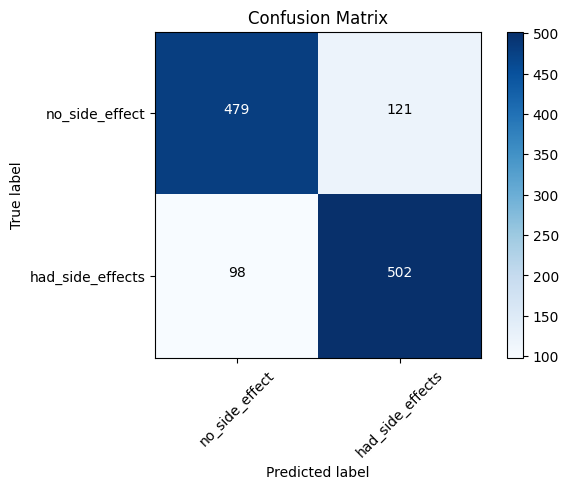

In [17]:
cm_plot_labels = ['no_side_effect', 'had_side_effects']
plot_confusion_matrix(cm=cm, classes=cm_plot_labels, title='Confusion Matrix')

Save the Model

In [19]:
import os.path
if os.path.isfile('models/medical_trial_data_model.keras') is False:
  model.save('models/medical_trial_data_model.keras')

In [21]:
from keras.models import load_model
new_md = load_model('models/medical_trial_data_model.keras')

Saved model summary

In [22]:
new_md.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,286 (5.03 KB)

 Trainable params: 642 (2.51 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 644 (2.52 KB)